# Project Setup

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf

plt.style.use('seaborn-v0_8-whitegrid')


# Loading and Handling the Data

In [ ]:

df_prices_raw = pd.read_csv('DayAheadPrices.csv', sep=';')


df_wind_raw = pd.read_csv('ElectricityProdex5MinRealtime.csv', sep=';')

print("Raw price shape:", df_prices_raw.shape)
print("Raw wind shape:", df_wind_raw.shape)

In [ ]:
# Convert price string to float
df_prices_raw['DayAheadPriceEUR'] = df_prices_raw['DayAheadPriceEUR'].str.replace(',', '.').astype(float)

# Convert UTC Timestamp to datetime (Prevents Daylight Saving Time duplicate errors)
df_prices_raw['TimeUTC'] = pd.to_datetime(df_prices_raw['TimeUTC'])

# Pivot prices to separate DK1 and DK2 columns
df_prices_piv = df_prices_raw.pivot(index='TimeUTC', columns='PriceArea', values='DayAheadPriceEUR')

# Resample sub-hourly data to 1-hour UTC averages
df_prices_hourly = df_prices_piv.resample('1h').mean().reset_index()
df_prices_hourly.rename(columns={'DK1': 'day_ahead_price_dk1', 'DK2': 'day_ahead_price_dk2'}, inplace=True)

# Calculate Spatial Spread (DK1 - DK2 Location Margin)
df_prices_hourly['dk1_dk2_spread'] = df_prices_hourly['day_ahead_price_dk1'] - df_prices_hourly['day_ahead_price_dk2']

df_prices_hourly.head()

# Adjusting Datetime

In [ ]:
df_wind = df_wind_raw.copy()

# Parse datetime 
df_wind['Minutes5UTC'] = pd.to_datetime(df_wind['Minutes5UTC'])


for col in ['OffshoreWindPower', 'OnshoreWindPower']:
    df_wind[col] = df_wind[col].astype(str).str.replace(',', '.').astype(float)

# Filter DK1 and compute total wind power in MW
df_wind_dk1 = df_wind[df_wind['PriceArea'] == 'DK1'].copy()
df_wind_dk1['total_wind_mw'] = df_wind_dk1['OffshoreWindPower'].fillna(0) + df_wind_dk1['OnshoreWindPower'].fillna(0)

# Resample to Hourly UTC (Floor timestamps to hour to guarantee exact match)
df_wind_dk1['TimeUTC'] = df_wind_dk1['Minutes5UTC'].dt.floor('h')
df_wind_hourly = df_wind_dk1.groupby('TimeUTC')['total_wind_mw'].mean().reset_index()

df_wind_hourly.head()

In [ ]:
# Guarantee price TimeUTC is also floored to hour
df_prices_hourly['TimeUTC'] = pd.to_datetime(df_prices_hourly['TimeUTC']).dt.floor('h')

df_merged = pd.merge(df_prices_hourly, df_wind_hourly, on='TimeUTC', how='inner')

print("Merged rows count:", len(df_merged))
print("\nTotal Wind MW Summary (Must not be zero!):")
print(df_merged['total_wind_mw'].describe())

df_merged.to_csv('dk1_dk2_wind_price_master.csv', index=False)

# Visualization

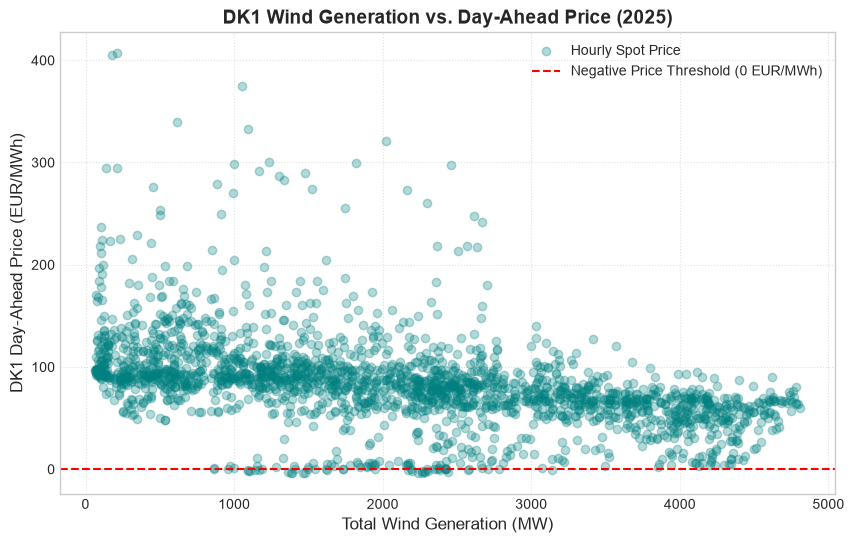

In [8]:
plt.figure(figsize=(10, 6))

# Plot Wind Generation vs DK1 Price
plt.scatter(df_merged['total_wind_mw'], df_merged['day_ahead_price_dk1'], alpha=0.3, color='#008080', label='Hourly Spot Price')

# Add Negative Price Boundary line
plt.axhline(0, color='red', linestyle='--', linewidth=1.5, label='Negative Price Threshold (0 EUR/MWh)')

# Labels and Styling
plt.title('DK1 Wind Generation vs. Day-Ahead Price (2025)', fontsize=14, fontweight='bold')
plt.xlabel('Total Wind Generation (MW)', fontsize=12)
plt.ylabel('DK1 Day-Ahead Price (EUR/MWh)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')

# Save and Show Plot
plt.savefig('wind_vs_price_scatter.png', dpi=300, bbox_inches='tight')
plt.show()